# Notebook 12 (Revised) — Cross-architecture development-CV synthesis

**Status:** Completed: read-only development-CV synthesis. This notebook creates **no model fits, predictions, new checkpoints, refits, or saved data files**. It uses only metrics already stored under `results/development_only/`.

### Scientific question

Across **Ridge, LightGBM, Random Forest, LSTM, TCN, GRU and BiLSTM**, which architecture, frozen configuration, and feature family has the lowest **unweighted mean MAE of three chronological outer development-validation folds** at the 15-, 30-, and 60-minute direct horizons? How stable are those differences across folds? Does adding lunar/Panchang features help when candidate configurations are held fixed?

### Strict boundaries

- **Excluded:** historical Notebook 11 terminal-test scores, older Notebooks 12–15 results, external PVOD scores, and **June–August 2019 terminal labels**. No paths outside the `results/development_only/` archives are read for *metrics*.
- **Permitted:** immutable `src` modules to validate archive source fingerprints, and development-only CSV/JSON scores. No SOLETE HDF5 input is loaded.
- **Ranking rule:** candidate MAE = simple average of the three *outer* fold MAEs (each fold equally weighted); RMSE is descriptive and not a selection tie-breaker. Within each model / horizon / family, ties are broken by `config_index`. Across families, ties use F0→F4 order; across models, a deterministic displayed order. A difference in CV MAE is descriptive, not an inferential p-value.
- **Not a selection-lock or terminal evaluation:** output is a proposed development-only shortlist pending review of population parity, fold variability, selection multiplicity and the final-refit policy.


In [1]:
# Read-only imports and location discovery. No heavy frameworks or source data loaded.
from pathlib import Path
from io import BytesIO
from itertools import product
from hashlib import sha256
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = []
if os.environ.get("SOLETE_PROJECT_ROOT"):
    candidates.append(Path(os.environ["SOLETE_PROJECT_ROOT"]).expanduser())
cwd = Path.cwd().resolve()
candidates.extend([cwd, cwd.parent, cwd.parent.parent])
PROJECT_ROOT = next((p.resolve() for p in candidates
                     if (p / "src/forecasting_protocol.py").is_file()
                     and (p / "results/development_only").is_dir()), None)
assert PROJECT_ROOT is not None, "Open from the SOLETE repository, or set SOLETE_PROJECT_ROOT"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DEV_ROOT = (PROJECT_ROOT / "results/development_only").resolve()
assert DEV_ROOT.is_dir()
HORIZONS = (15, 30, 60)
FAMILIES = ("F0", "F1", "F2", "F3", "F4")
MODELS = ("Ridge", "LightGBM", "RandomForest", "LSTM", "TCN", "GRU", "BiLSTM")
CLASSICAL_CONFIG_COUNTS = {"Ridge":5, "LightGBM":8, "RandomForest":8}
NEURAL_CONFIG_COUNTS = {"LSTM":4,"TCN":4,"GRU":4,"BiLSTM":4}
CONFIG_COUNTS = {**CLASSICAL_CONFIG_COUNTS, **NEURAL_CONFIG_COUNTS}

# Hard guard: every metric input must live under the development-only directory.
def development_file(relative_path):
    p = (DEV_ROOT / relative_path).resolve()
    assert p.is_relative_to(DEV_ROOT), "Forbidden result path outside development-only"
    assert p.is_file(), f"Missing frozen development-CV artifact: {p}"
    return p

print("Repository:", PROJECT_ROOT)
print("Metric input scope:", DEV_ROOT)
print("Analysis only: no training, no terminal labels, no output files")

Repository: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project
Metric input scope: /Users/siddharthgupta/Downloads/NSUT/Semester 1/MTITC102 AI and Machine Learning/Project/results/development_only
Analysis only: no training, no terminal labels, no output files


## 1. Audit the classical CSV archives (Ridge and LightGBM)

Verify every file against the checksums and row counts written at archival time, before reading any metric. Do not run Notebook 10's training cells. The two manifests also preserve a historical source fingerprint; no source changes are attempted here.

In [2]:
def read_manifest_archive(model, subdir, prefix, expected_rows):
    rel = f"revised_classical_cv_v1/{subdir}"
    manifest = json.loads(development_file(f"{rel}/manifest.json").read_text(encoding="utf-8"))
    assert isinstance(manifest.get("source_sha256"), str) and len(manifest["source_sha256"]) == 64
    assert manifest.get("terminal_test_evaluated") is not True
    tables = {}
    for logical, count in expected_rows.items():
        filename = f"{prefix}_{logical}.csv"
        entry = manifest["files"][filename]
        data = development_file(f"{rel}/{filename}").read_bytes()
        assert sha256(data).hexdigest() == entry["sha256"], f"SHA-256 mismatch: {filename}"
        table = pd.read_csv(BytesIO(data))
        assert len(table) == count == entry["rows"], f"Row count mismatch: {filename}"
        tables[logical] = table
    return tables, manifest

ridge_tables, ridge_manifest = read_manifest_archive(
    "Ridge", "ridge", "ridge", {"fold_scores":225, "candidate_rankings":75, "selected":15, "runtimes":15})
lgb_tables, lgb_manifest = read_manifest_archive(
    "LightGBM", "lightgbm", "lightgbm", {"fold_scores":360, "candidate_rankings":120, "selected":15, "runtimes":15})

needed = {"horizon_minutes", "feature_family", "config_index", "configuration",
          "fold", "train_rows", "validation_rows", "validation_mae", "validation_rmse"}
def standardized_classical_csv(scores, model):
    assert needed.issubset(scores.columns), (model, set(scores.columns))
    t = scores.copy()
    t["model"] = model
    t["candidate_id"] = model + "_C" + (t["config_index"].astype(int) + 1).astype(str)
    t["configuration_json"] = t["configuration"].apply(lambda x: json.dumps(json.loads(x), sort_keys=True))
    t = t.rename(columns={"validation_mae":"validation_mae_kw",
                          "validation_rmse":"validation_rmse_kw"})
    t["source_archive"] = model + ":manifest-verified-csv"
    return t

ridge_cv = standardized_classical_csv(ridge_tables["fold_scores"], "Ridge")
lgb_cv = standardized_classical_csv(lgb_tables["fold_scores"], "LightGBM")
print("Ridge: SHA-verified 225 fold scores / 75 candidate rankings")
print("LightGBM: SHA-verified 360 fold scores / 120 candidate rankings")

Ridge: SHA-verified 225 fold scores / 75 candidate rankings
LightGBM: SHA-verified 360 fold scores / 120 candidate rankings


## 2. Audit Random Forest's checkpointed JSON archives

Random Forest was saved as 15 horizon×family blocks, each containing 8 configurations×3 folds. Validate the file schema, source fingerprint, expected model identity and key uniqueness without invoking its fitting runner. The archived `signature_sha256` is retained as stored metadata; this notebook does not reconstruct training arrays to recompute it.

In [3]:
# Identical byte concatenation/order used by frozen Notebook 10's RF runner.
_rf_sources = ("src/classical_models.py", "src/revised_classical_cv.py",
               "src/forecasting_protocol.py", "src/revised_rf_checkpoint.py")
rf_source_digest = sha256(b"".join((PROJECT_ROOT / name).read_bytes() for name in _rf_sources)).hexdigest()
rf_rows = []
for horizon, family in product(HORIZONS, FAMILIES):
    artifact = development_file(f"revised_classical_cv_v1/random_forest/h{horizon}_{family}.json")
    saved = json.loads(artifact.read_text(encoding="utf-8"))
    assert saved["model"] == "RandomForestRegressor"
    assert saved["horizon_minutes"] == horizon and saved["feature_family"] == family
    assert saved["schema_version"] == 1
    assert saved["source_sha256"] == rf_source_digest, f"RF frozen source changed: {artifact}"
    assert isinstance(saved["signature_sha256"], str) and len(saved["signature_sha256"]) == 64
    configurations, fits = saved["candidate_configurations"], saved["fits"]
    assert len(configurations) == 8 and len(fits) == 24
    assert {(int(f["config_index"]), int(f["fold"])) for f in fits} == set(product(range(8), (1,2,3)))
    for rec in fits:
        i = int(rec["config_index"])
        rf_rows.append({
            "model":"RandomForest", "horizon_minutes":horizon, "feature_family":family,
            "config_index":i, "candidate_id":f"RandomForest_C{i+1}",
            "configuration_json":json.dumps(configurations[i], sort_keys=True),
            "fold":int(rec["fold"]), "train_rows":int(rec["train_rows"]),
            "validation_rows":int(rec["validation_rows"]),
            "validation_mae_kw":float(rec["validation_mae"]),
            "validation_rmse_kw":float(rec["validation_rmse"]),
            "source_archive":"RandomForest:source-verified-json",
        })
rf_cv = pd.DataFrame(rf_rows)
assert len(rf_cv) == 360
print("Random Forest: 15 source-verified files, 360 fold scores, 120 candidates")

Random Forest: 15 source-verified files, 360 fold scores, 120 candidates


## 3. Verify all 720 archived neural CV evaluations

Use the frozen *reader/audit* functions only—**never call** `run_one_cv`, `run_batch`, or `fit`. V1 F0 and V2 F1–F4 source digests must match their recorded identities. The GRU/BiLSTM extension additionally verifies both frozen implementations, its own extension source, and the per-fold data hashes against the original LSTM inputs.

In [4]:
from src.revised_neural_campaign import campaign_source_sha256 as neural_v1_sha
from src.revised_neural_campaign_v2 import campaign_source_sha256 as neural_v2_sha
from src.revised_neural_batch import _audit_prior_source
from src.revised_neural_batch_v2 import _audit_v2, read_mixed_progress
from src.revised_recurrent_extension import read_progress as read_recurrent_progress
from src.forecasting_protocol import EXPECTED_CV_COUNTS_BY_HORIZON

orig_v1 = DEV_ROOT / "revised_neural_cv_v1"
orig_v2 = DEV_ROOT / "revised_neural_cv_v2_year_std1"
assert _audit_prior_source(orig_v1, source_sha256=neural_v1_sha(PROJECT_ROOT)) == 72
assert _audit_v2(orig_v2, neural_v2_sha(PROJECT_ROOT)) == 288
original_neural = read_mixed_progress(orig_v1, orig_v2)
recurrent_neural = read_recurrent_progress(PROJECT_ROOT)  # source/schema/config audits
assert len(original_neural) == 360 and len(recurrent_neural) == 360
assert set(original_neural["model"]) == {"LSTM", "TCN"}
assert set(recurrent_neural["model"]) == {"GRU", "BiLSTM"}

# Cross-check archived training populations and raw-data identities using JSON
# metadata only. No raw predictors, training targets or terminal data are read.
_neural_rows = []
for frame in (original_neural, recurrent_neural):
    for row in frame.itertuples(index=False):
        directory = ("revised_neural_cv_v1" if row.feature_family == "F0" else
                     "revised_neural_cv_v2_year_std1") if row.model in ("LSTM", "TCN") else (
                     "revised_recurrent_extension_v1_F0" if row.feature_family == "F0" else
                     "revised_recurrent_extension_v2_year_std1")
        filename = f"{row.model.lower()}_c{row.config_index + 1}_h{row.horizon_minutes}_{row.feature_family}_fold{row.fold}.json"
        state = json.loads(development_file(f"{directory}/{filename}").read_text(encoding="utf-8"))
        ident = state["identity"]
        assert (ident["model"], ident["horizon_minutes"], ident["feature_family"],
                ident["config_index"], ident["outer_fold"]) == (
                row.model, row.horizon_minutes, row.feature_family, row.config_index, row.fold)
        expected_train, expected_val = EXPECTED_CV_COUNTS_BY_HORIZON[row.horizon_minutes][row.fold-1]
        assert (ident["outer_train_rows"], ident["outer_validation_rows"]) == (expected_train, expected_val)
        assert state["record"]["validation_mae_kw"] == row.validation_mae_kw
        assert state["record"]["validation_rmse_kw"] == row.validation_rmse_kw
        _neural_rows.append({
            "model":row.model,"horizon_minutes":row.horizon_minutes,
            "feature_family":row.feature_family,"config_index":row.config_index,
            "candidate_id":row.candidate_id,"configuration_json":json.dumps(ident["configuration"], sort_keys=True),
            "fold":row.fold,"train_rows":expected_train,"validation_rows":expected_val,
            "validation_mae_kw":row.validation_mae_kw,"validation_rmse_kw":row.validation_rmse_kw,
            "source_archive": "Neural:source-and-schema-verified-json",
            "data_sha256":ident["data_sha256"],"best_epoch":row.best_epoch,
        })
neural_cv = pd.DataFrame(_neural_rows)
_reference = (neural_cv[neural_cv["model"] == "LSTM"]
              .query("config_index == 0")
              .set_index(["horizon_minutes","feature_family","fold"])["data_sha256"])
assert len(_reference) == 45
for row in neural_cv.itertuples(index=False):
    assert row.data_sha256 == _reference.loc[(row.horizon_minutes, row.feature_family, row.fold)], (
        "Input mismatch", row.model, row.horizon_minutes, row.feature_family, row.fold)
assert len(neural_cv) == 720
print("Neural: 720/720 source-, schema-, fold- and input-population-verified scores")

Neural: 720/720 source-, schema-, fold- and input-population-verified scores


## 4. Unified 1,665-score integrity gate

The three classical models contribute 225 + 360 + 360 = **945** evaluations; four neural models contribute **720**. Audit exact Cartesian coverage and the **same train/validation populations** for every candidate. This is an audit of archived CV *summary scores*, not raw predictions or paired per-timestamp errors.

In [5]:
COLUMNS = ["model", "horizon_minutes", "feature_family", "config_index", "candidate_id",
           "configuration_json", "fold", "train_rows", "validation_rows",
           "validation_mae_kw", "validation_rmse_kw", "source_archive"]
all_cv = pd.concat([ridge_cv[COLUMNS], lgb_cv[COLUMNS], rf_cv[COLUMNS], neural_cv[COLUMNS]],
                   ignore_index=True)
KEY = ["model", "horizon_minutes", "feature_family", "config_index", "fold"]
expected_keys = set().union(*(set(product((m,), HORIZONS, FAMILIES, range(count), (1,2,3)))
                             for m,count in CONFIG_COUNTS.items()))
assert len(all_cv) == 1665 and len(expected_keys) == 1665
actual_keys = set(all_cv[KEY].itertuples(index=False, name=None))
assert actual_keys == expected_keys, f"Missing={len(expected_keys-actual_keys)} / extra={len(actual_keys-expected_keys)}"
assert not all_cv.duplicated(KEY).any()
assert all_cv["configuration_json"].notna().all()
assert (all_cv.groupby(["model", "horizon_minutes", "feature_family", "config_index"])
        ["configuration_json"].nunique() == 1).all()
metric_cols = ["validation_mae_kw", "validation_rmse_kw"]
assert np.isfinite(all_cv[metric_cols].to_numpy(dtype=float)).all()
assert (all_cv[metric_cols] >= 0).all().all()
assert (all_cv["validation_rmse_kw"] + 1e-8 >= all_cv["validation_mae_kw"]).all()
for row in all_cv.itertuples(index=False):
    assert (row.train_rows,row.validation_rows) == EXPECTED_CV_COUNTS_BY_HORIZON[row.horizon_minutes][row.fold-1], (
        row.model, row.horizon_minutes, row.feature_family, row.config_index, row.fold)
assert (all_cv.groupby(["model","horizon_minutes","feature_family","config_index"])
        ["fold"].nunique() == 3).all()
print("UNIFIED DEVELOPMENT CV AUDIT: PASSED — 1,665/1,665 candidate-fold scores")
print("Models=7 | Horizons=3 | Feature families=5 | Outer folds=3")
print("Original checkpoint/CSV SHA and frozen-source checks: PASSED")
print("Temporal training/validation populations: MATCH across all architectures")
print("Terminal data and historical test results: NOT READ")
display(all_cv.groupby("model").size().reindex(MODELS).rename("verified_fold_scores").reset_index())

UNIFIED DEVELOPMENT CV AUDIT: PASSED — 1,665/1,665 candidate-fold scores
Models=7 | Horizons=3 | Feature families=5 | Outer folds=3
Original checkpoint/CSV SHA and frozen-source checks: PASSED
Temporal training/validation populations: MATCH across all architectures
Terminal data and historical test results: NOT READ


,model,verified_fold_scores
0,Ridge,225
1,LightGBM,360
2,RandomForest,360
3,LSTM,180
4,TCN,180
5,GRU,180
6,BiLSTM,180


## 5. Candidate ranking and overall development shortlists

For each candidate: **mean of the 3 outer-fold MAEs**; RMSE is also averaged by fold. Do **not** average the RMSEs by recomputing an RMSE over the three fold-level RMSEs; those are different estimands. Show the best configuration within each feature family, the best family per architecture/horizon and the best across all seven architectures per horizon. These are *development-CV nominations*, not final refit/test claims.

In [6]:
group_keys = ["model", "horizon_minutes", "feature_family", "config_index", "candidate_id", "configuration_json"]
candidate_summary = (all_cv.groupby(group_keys, as_index=False)
    .agg(cv_mae_kw=("validation_mae_kw","mean"),
         cv_rmse_kw=("validation_rmse_kw","mean"),
         fold_mae_std_kw=("validation_mae_kw","std"),
         min_fold_mae_kw=("validation_mae_kw","min"),
         max_fold_mae_kw=("validation_mae_kw","max"),
         folds=("fold","nunique")))
assert len(candidate_summary) == 555 and (candidate_summary["folds"] == 3).all()
candidate_summary["fold_range_kw"] = candidate_summary["max_fold_mae_kw"] - candidate_summary["min_fold_mae_kw"]
candidate_summary["model_order"] = candidate_summary["model"].map({m:i for i,m in enumerate(MODELS)})
candidate_summary["family_order"] = candidate_summary["feature_family"].map({f:i for i,f in enumerate(FAMILIES)})
candidate_summary = candidate_summary.sort_values(
    ["horizon_minutes","model_order","family_order","cv_mae_kw","config_index"], kind="stable")
candidate_summary["rank_in_family"] = (
    candidate_summary.groupby(["model","horizon_minutes","feature_family"]).cumcount()+1)
family_winners = candidate_summary.query("rank_in_family == 1").copy()
assert len(family_winners) == 105

model_horizon_winners = (candidate_summary.sort_values(
    ["horizon_minutes","model_order","cv_mae_kw","family_order","config_index"], kind="stable")
    .drop_duplicates(["model","horizon_minutes"])
    .sort_values(["horizon_minutes","cv_mae_kw","model_order"], kind="stable").reset_index(drop=True))
assert len(model_horizon_winners) == 21
horizon_shortlist = (model_horizon_winners.drop_duplicates("horizon_minutes")
                     .sort_values("horizon_minutes").reset_index(drop=True))
assert len(horizon_shortlist) == 3
SHOW = ["horizon_minutes","model","feature_family","candidate_id",
        "cv_mae_kw","cv_rmse_kw","fold_mae_std_kw","fold_range_kw"]
print("All 7 × 3 architecture-horizon winners (21 rows)")
display(model_horizon_winners[SHOW].round(6))
print("Development-CV lowest-MAE nominees across all 7 architectures")
display(horizon_shortlist[SHOW + ["configuration_json"]].round(6))

All 7 × 3 architecture-horizon winners (21 rows)


,horizon_minutes,model,feature_family,candidate_id,cv_mae_kw,cv_rmse_kw,fold_mae_std_kw,fold_range_kw
0,15,LightGBM,F1,LightGBM_C1,0.177400,0.451460,0.088176,0.176258
1,15,RandomForest,F2,RandomForest_C3,0.177618,0.455851,0.089783,0.179339
2,15,BiLSTM,F0,BiLSTM_C2,0.200565,0.492169,0.077607,0.150466
3,15,GRU,F0,GRU_C1,0.205875,0.494369,0.089483,0.177529
4,15,LSTM,F0,LSTM_C1,0.206821,0.493383,0.090654,0.176833
5,15,Ridge,F0,Ridge_C1,0.223734,0.474716,0.073087,0.144947
6,15,TCN,F4,TCN_C1,0.327693,0.585264,0.097514,0.177418
7,30,LightGBM,F2,LightGBM_C1,0.219329,0.517169,0.098119,0.195311
8,30,RandomForest,F1,RandomForest_C8,0.225092,0.540882,0.098928,0.196818
9,30,BiLSTM,F0,BiLSTM_C1,0.242536,0.582941,0.098810,0.196923


Development-CV lowest-MAE nominees across all 7 architectures


,horizon_minutes,model,feature_family,candidate_id,cv_mae_kw,cv_rmse_kw,fold_mae_std_kw,fold_range_kw,configuration_json
0,15,LightGBM,F1,LightGBM_C1,0.177400,0.451460,0.088176,0.176258,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""..."
1,30,LightGBM,F2,LightGBM_C1,0.219329,0.517169,0.098119,0.195311,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""..."
2,60,LightGBM,F2,LightGBM_C1,0.280951,0.612719,0.100403,0.197555,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""..."


### 5.1 Selection margin and fold-to-fold consistency

A tiny score gap (particularly at 15 minutes) should not be over-interpreted. For each horizon, compare the winning **full (architecture, feature family, configuration)** tuple to the runner-up from a *different architecture*. The identical chronological scored fold populations permit a descriptive **3-fold MAE-difference** comparison even when the feature family differs. Three aggregated folds do **not** provide a valid basis for a significance claim, and model selection across 555 candidates introduces optimism.

In [7]:
ranked_architectures = model_horizon_winners.sort_values(
    ["horizon_minutes","cv_mae_kw","model_order"], kind="stable").copy()
margin_rows = []
paired_rows = []
for h in HORIZONS:
    pair = ranked_architectures.query("horizon_minutes == @h").iloc[:2]
    winner, runner = pair.iloc[0], pair.iloc[1]
    delta = float(runner.cv_mae_kw - winner.cv_mae_kw)
    assert delta >= -1e-12
    margin_rows.append({"horizon_minutes":h, "winner":winner.model,
                        "winner_family":winner.feature_family,
                        "winner_cv_mae_kw":winner.cv_mae_kw,
                        "runner_up":runner.model,"runner_up_family":runner.feature_family,
                        "runner_cv_mae_kw":runner.cv_mae_kw,
                        "margin_kw":delta,"margin_pct_of_runner":100*delta/runner.cv_mae_kw})
    def candidate_folds(z):
        return (all_cv[(all_cv["model"]==z.model)&(all_cv["horizon_minutes"]==h)&
                       (all_cv["feature_family"]==z.feature_family)&
                       (all_cv["config_index"]==z.config_index)]
                .set_index("fold")["validation_mae_kw"].loc[[1,2,3]])
    a,b = candidate_folds(winner),candidate_folds(runner)
    for fold in (1,2,3):
        paired_rows.append({"horizon_minutes":h,"fold":fold,
                            "winning_model":winner.model,"runner_up":runner.model,
                            "winner_mae_kw":float(a[fold]),"runner_mae_kw":float(b[fold]),
                            "runner_minus_winner_kw":float(b[fold]-a[fold])})
finalist_margins = pd.DataFrame(margin_rows)
finalist_fold_deltas = pd.DataFrame(paired_rows)
assert len(finalist_fold_deltas) == 9
print("Winner / runner-up by horizon")
display(finalist_margins.round(6))
print("Paired difference on the three *aggregated* outer validation folds")
display(finalist_fold_deltas.round(6))
print("No confidence intervals or p-values are inferred from the three CV folds")

Winner / runner-up by horizon


,horizon_minutes,winner,winner_family,winner_cv_mae_kw,runner_up,runner_up_family,runner_cv_mae_kw,margin_kw,margin_pct_of_runner
0,15,LightGBM,F1,0.177400,RandomForest,F2,0.177618,0.000218,0.122994
1,30,LightGBM,F2,0.219329,RandomForest,F1,0.225092,0.005763,2.560447
2,60,LightGBM,F2,0.280951,RandomForest,F1,0.286863,0.005912,2.060989


Paired difference on the three *aggregated* outer validation folds


,horizon_minutes,fold,winning_model,runner_up,winner_mae_kw,runner_mae_kw,runner_minus_winner_kw
0,15,1,LightGBM,RandomForest,0.087600,0.085340,-0.002259
1,15,2,LightGBM,RandomForest,0.180742,0.182835,0.002093
2,15,3,LightGBM,RandomForest,0.263858,0.264680,0.000822
3,30,1,LightGBM,RandomForest,0.116172,0.120838,0.004666
4,30,2,LightGBM,RandomForest,0.230332,0.236783,0.006451
5,30,3,LightGBM,RandomForest,0.311483,0.317656,0.006173
6,60,1,LightGBM,RandomForest,0.171786,0.171239,-0.000547
7,60,2,LightGBM,RandomForest,0.301726,0.310267,0.008541
8,60,3,LightGBM,RandomForest,0.369341,0.379083,0.009742


No confidence intervals or p-values are inferred from the three CV folds


## 6. Feature-family ablation and F3 → F4 matched-configuration analysis

Two different questions must be kept separate:

1. **Within-family tuned best:** select the best C1–Ck separately for each feature family, then compare F0, F1, F2, F3, F4. This is useful for *model selection* but includes selection flexibility.
2. **Fixed-configuration F3/F4:** hold model, horizon and `config_index` constant, then subtract F3 from F4 MAE. A negative value favors Panchang addition **on that candidate**. This is a cleaner representation ablation, but still uses observed development folds, and no causal conclusion follows from CV scores alone.

Do not compare cross-family feature effects against the **historical terminal TEST** notebook. V1 F0 and V2 F1–F4 have documented scaling differences for neural models; that provenance qualifies broader cross-family comparisons.

In [8]:
family_matrix = family_winners.pivot(index=["model","horizon_minutes"],
    columns="feature_family",values="cv_mae_kw").reindex(columns=FAMILIES)
assert family_matrix.shape == (21,5)
print("Best candidate in each family — three-fold CV MAE in kW")
display(family_matrix.round(6))

f3 = candidate_summary[candidate_summary.feature_family == "F3"]
f4 = candidate_summary[candidate_summary.feature_family == "F4"]
compare_keys = ["model","horizon_minutes","config_index"]
paired_f3_f4 = f3[compare_keys+["cv_mae_kw"]].merge(
    f4[compare_keys+["cv_mae_kw"]],on=compare_keys,
    suffixes=("_F3","_F4"),validate="one_to_one")
paired_f3_f4["F4_minus_F3_kw"] = paired_f3_f4["cv_mae_kw_F4"] - paired_f3_f4["cv_mae_kw_F3"]
# Three horizons × (5 Ridge + 8 LightGBM + 8 RF + 4×4 neural) = 111 pairs.
assert len(paired_f3_f4) == 111
matched_f4_summary = (paired_f3_f4.groupby(["model","horizon_minutes"],as_index=False)
    .agg(configurations=("config_index","size"),
         mean_F4_minus_F3_kw=("F4_minus_F3_kw","mean"),
         F4_lower_count=("F4_minus_F3_kw",lambda x:int((x<0).sum()))))
assert len(matched_f4_summary) == 21
print("F3 → F4 with configuration held fixed (negative MAE change favors F4)")
display(matched_f4_summary.round(6))

Best candidate in each family — three-fold CV MAE in kW


feature_family                      F0        F1        F2        F3        F4
model        horizon_minutes                                                  
BiLSTM       15               0.200565  0.263973  0.227600  0.230290  0.218282
             30               0.242536  0.301893  0.285513  0.268845  0.282405
             60               0.322029  0.326201  0.355773  0.308861  0.337557
GRU          15               0.205875  0.208510  0.246920  0.224423  0.239570
             30               0.261179  0.273950  0.318524  0.289256  0.290742
             60               0.341018  0.356374  0.374408  0.405096  0.394781
LSTM         15               0.206821  0.232145  0.235256  0.270439  0.240270
             30               0.260960  0.281023  0.341875  0.306357  0.304457
             60               0.346670  0.398943  0.374726  0.378638  0.379059
LightGBM     15               0.186805  0.177400  0.178696  0.180784  0.179828
             30               0.243146  0.220946  0.219329  0.221195  0.222238
             60               0.326559  0.287611  0.280951  0.285970  0.284991
RandomForest 15               0.182358  0.179036  0.177618  0.179622  0.179598
             30               0.237948  0.225092  0.226551  0.229083  0.227636
             60               0.322818  0.286863  0.291135  0.295827  0.294765
Ridge        15               0.223734  0.306610  0.306517  0.264452  0.303371
             30               0.301027  0.442702  0.443909  0.360826  0.444886
             60               0.421255  0.669405  0.678198  0.508959  0.684748
TCN          15               0.604037  1.167045  0.589501  0.659632  0.327693
             30               0.472601  0.527562  0.520028  0.619224  0.539749
             60               0.536669  0.542134  0.501114  0.641698  0.595898

F3 → F4 with configuration held fixed (negative MAE change favors F4)


,model,horizon_minutes,configurations,mean_F4_minus_F3_kw,F4_lower_count
0,BiLSTM,15,4,-0.023255,3
1,BiLSTM,30,4,0.034180,0
2,BiLSTM,60,4,0.022631,0
3,GRU,15,4,0.013106,2
4,GRU,30,4,0.009305,1
5,GRU,60,4,-0.011311,3
6,LSTM,15,4,-0.042648,4
7,LSTM,30,4,0.000387,2
8,LSTM,60,4,-0.009550,2
9,LightGBM,15,8,0.000308,4


## 7. Cross-architecture visualization (development scores only)

A visual summary of the **best family/configuration per architecture/horizon**. The bars are means of three outer validation-fold MAEs, not terminal/test errors. Differences are selected minima from grids of different sizes, and a chart alone should not be interpreted as proof of generalization superiority.

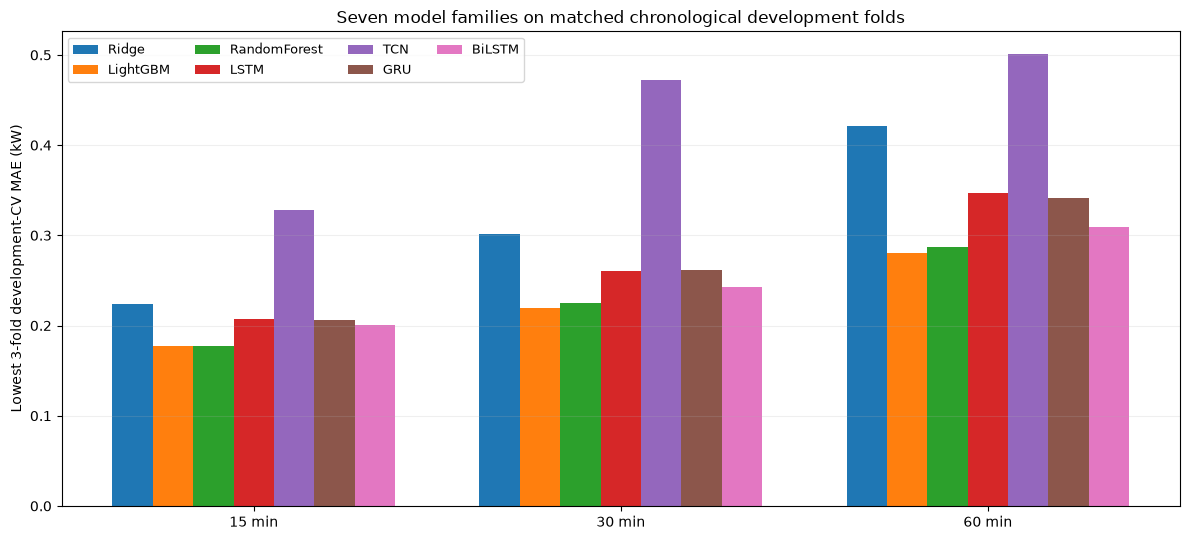

In [9]:
fig, ax = plt.subplots(figsize=(12,5.5))
x = np.arange(len(HORIZONS))
width = 0.11
for i, model in enumerate(MODELS):
    scores = (model_horizon_winners[model_horizon_winners.model.eq(model)]
              .set_index("horizon_minutes").loc[list(HORIZONS),"cv_mae_kw"].to_numpy())
    ax.bar(x+(i-(len(MODELS)-1)/2)*width,scores,width,label=model)
ax.set_xticks(x,[f"{h} min" for h in HORIZONS])
ax.set_ylabel("Lowest 3-fold development-CV MAE (kW)")
ax.set_title("Seven model families on matched chronological development folds")
ax.legend(ncol=4,fontsize=9)
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
plt.show()

## 8. Reproducibility and methodological limits

**Checks performed by this notebook:** archived Ridge/LightGBM bytes equal SHA manifest hashes; RF checkpointed results have expected keys/source digest; neural readers verify schema and frozen source; all neural data hashes match the LSTM reference within the same horizon/family/fold; all 1,665 records have expected chronological fold populations and nonnegative finite kW metrics.

**Things this notebook deliberately does not establish:** per-timestamp residual dependence, calibrated uncertainty, causal effects of Panchang representations, absolute forecast skill against an independent untouched test, production deployment readiness, or final full-development refit epochs.

**Historical holdout qualification:** the old research already inspected June–August 2019. Therefore it is *excluded from current model selection*, but it cannot be described as never observed across the full project history. Any subsequent use must disclose that prior exposure.

**Backend and representation provenance:** neural LSTM/TCN and GRU/BiLSTM were developed across different CPU/Metal execution stages; individual numerical results need not be bitwise identical across backends. F1–F4 neural runs use the source-verified year-safe V2 scaling whereas F0 uses V1. This notebook combines archived outcomes only; it does not change training policy.

**Model-selection multiplicity:** 555 candidate sets are screened. Even where mean MAE gaps appear favorable, a candidate with a narrow winning margin might not be reliably better on future periods. Give the 15-minute LightGBM-versus-RandomForest close comparison particular attention before freezing a decision.

## 9. Proposed selection-review checklist — **not a lock**

The table below is the **development-CV nominated shortlist**, not a terminal model list. Before authorizing a final refit:

- [ ] Confirm audit prints `1,665/1,665`, and both archives remain unchanged under Git.
- [ ] Check best and runner-up configuration JSON, fold-level error vectors and within-family scaling provenance.
- [ ] Decide whether the strict minimum mean MAE or a predeclared practical-tolerance/simple-model rule governs near ties; state it **before** any terminal results are examined.
- [ ] Confirm final deployment features use only information available at forecast **issue time** (observed history and permitted deterministic ephemeris/calendar quantities).
- [ ] Freeze per-horizon architecture, feature family, configuration, random seeds, train-only preprocessing, final epoch/refit method, backend and package versions in a separate selection record.
- [ ] Review historical terminal-period exposure and describe the limitation transparently.
- [ ] Only then design any subsequent validation or mechanism/external-dataset study. Do **not** launch a terminal evaluation from this notebook.

**Next notebook after this synthesis:** an explicitly approved selection-lock and final-refit protocol, with a separate run gate. Older Notebooks 12–15 remain unchanged.

In [10]:
# Read-only proposal data structure. This does not write a lock file or start a refit.
proposed_review = horizon_shortlist[[
    "horizon_minutes","model","feature_family","config_index","candidate_id",
    "configuration_json","cv_mae_kw","cv_rmse_kw","fold_mae_std_kw"]].copy()
proposed_review.insert(0,"status","DEVELOPMENT_CV_NOMINEE_NOT_FROZEN")
display(proposed_review.round(6))
print("REVISED NOTEBOOK 12 READ-ONLY SYNTHESIS: FINISHED — no training or terminal evaluation")

,status,horizon_minutes,model,feature_family,config_index,candidate_id,configuration_json,cv_mae_kw,cv_rmse_kw,fold_mae_std_kw
0,DEVELOPMENT_CV_NOMINEE_NOT_FROZEN,15,LightGBM,F1,0,LightGBM_C1,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""...",0.177400,0.451460,0.088176
1,DEVELOPMENT_CV_NOMINEE_NOT_FROZEN,30,LightGBM,F2,0,LightGBM_C1,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""...",0.219329,0.517169,0.098119
2,DEVELOPMENT_CV_NOMINEE_NOT_FROZEN,60,LightGBM,F2,0,LightGBM_C1,"{""learning_rate"": 0.03, ""n_estimators"": 300, ""...",0.280951,0.612719,0.100403


REVISED NOTEBOOK 12 READ-ONLY SYNTHESIS: FINISHED — no training or terminal evaluation
